In [35]:
import pandas as pd
df = pd.read_csv("18_coffee_raw.csv")
print("we reead whole csv with padnas" )
#  right now dates are strings, not dates and quantity is string
df.dtypes

we reead whole csv with padnas


Loyalty Points Used      str
Payment Method           str
Customer Type            str
Barista                  str
Unit Price             int64
Quantity               int64
product_name_raw         str
Product Category         str
Time of Day              str
Order Date               str
Shop Branch              str
Order ID                 str
dtype: object

In [36]:
df2 = pd.read_csv("18_coffee_lookup.csv")


# Task 1. Initial Data Exploration

In [37]:
# 1.1 first 10 rows ...
df.head(10)

,Loyalty Points Used,Payment Method,Customer Type,Barista,Unit Price,Quantity,product_name_raw,Product Category,Time of Day,Order Date,Shop Branch,Order ID
0,Karakol,Basic,Premium,Basic,40737,38,Item G,Category D,Yes,2025-10-14,Jalal-Abad,18_-00000
1,Karakol,Standard,Basic,Basic,32592,4,Item D,Category C,No,25.09.2025,Osh,18_-00001
2,Bishkek,Premium,Standard,Standard,18214,41,Item C,Category D,No,19.02.2025,Bishkek,18_-00002
3,Osh,Basic,Standard,Premium,20283,35,Item F,Category B,Yes,2024-11-19,Tokmok,18_-00003
4,Bishkek,Standard,Standard,Premium,14992,29,Item B,Category C,No,16.12.2025,Osh,18_-00004
5,Karakol,Basic,Standard,Basic,5335,22,Item B,Category C,No,16.06.2024,Karakol,18_-00005
6,Tokmok,Standard,Premium,Premium,3505,30,Item E,Category A,Yes,21.03.2025,Osh,18_-00006
7,Bishkek,Premium,Basic,Standard,25963,7,Item B,Category B,No,2025-03-30,Jalal-Abad,18_-00007
8,Osh,Basic,Premium,Standard,22163,38,Item E,Category C,No,25.04.2024,Osh,18_-00008
9,Bishkek,Premium,Standard,Basic,37590,9,Item A,Category A,Yes,2025-12-14,Karakol,18_-00009


In [38]:
# 1.2 missing values in every column
#  "N/A" text turned into NaN automatically
print("raw:")
print(df.isna().sum())
print()
print("lookup: ")
print(df2.isna().sum())

raw:
Loyalty Points Used     0
Payment Method          0
Customer Type           0
Barista                 0
Unit Price              0
Quantity                0
product_name_raw        0
Product Category       13
Time of Day            13
Order Date              0
Shop Branch             0
Order ID                0
dtype: int64

lookup: 
Product Category    1
Business Segment    0
Priority            0
dtype: int64


In [39]:
# 1.3 number of rows and columns
print("raw:", df.shape)
print("lookup:", df2.shape)

raw: (840, 12)
lookup: (9, 3)


In [40]:
# 1.4 column names and data types
df.info()

print("\n lookup")
df2.info()

<class 'pandas.DataFrame'>
RangeIndex: 840 entries, 0 to 839
Data columns (total 12 columns):
 #   Column               Non-Null Count  Dtype
---  ------               --------------  -----
 0   Loyalty Points Used  840 non-null    str  
 1   Payment Method       840 non-null    str  
 2   Customer Type        840 non-null    str  
 3   Barista              840 non-null    str  
 4   Unit Price           840 non-null    int64
 5   Quantity             840 non-null    int64
 6   product_name_raw     840 non-null    str  
 7   Product Category     827 non-null    str  
 8   Time of Day          827 non-null    str  
 9   Order Date           840 non-null    str  
 10  Shop Branch          840 non-null    str  
 11  Order ID             840 non-null    str  
dtypes: int64(2), str(10)
memory usage: 78.9 KB

 lookup
<class 'pandas.DataFrame'>
RangeIndex: 9 entries, 0 to 8
Data columns (total 3 columns):
 #   Column            Non-Null Count  Dtype
---  ------            --------------  ----

In [41]:
# 1.5 Identify duplicate records using .duplicated().sum() and show several examples.
print("exact duplicate rows:", df.duplicated().sum())
# keep=False shows both copies of every duplicated record
df[df.duplicated(keep=False)].sort_values("Order ID").head(8)

# keep False means we do show all dublicates

exact duplicate rows: 19


,Loyalty Points Used,Payment Method,Customer Type,Barista,Unit Price,Quantity,product_name_raw,Product Category,Time of Day,Order Date,Shop Branch,Order ID
28,Bishkek,Basic,Premium,Premium,989,5,Item D,Category C,No,2025-10-30,Bishkek,18_-00028
837,Bishkek,Basic,Premium,Premium,989,5,Item D,Category C,No,2025-10-30,Bishkek,18_-00028
831,Jalal-Abad,Basic,Premium,Standard,40221,39,Item C,Category A,No,08.01.2025,Karakol,18_-00228
228,Jalal-Abad,Basic,Premium,Standard,40221,39,Item C,Category A,No,08.01.2025,Karakol,18_-00228
835,Osh,Premium,Basic,Standard,34939,33,Item H,Category D,Yes,2025-10-12,Bishkek,18_-00236
236,Osh,Premium,Basic,Standard,34939,33,Item H,Category D,Yes,2025-10-12,Bishkek,18_-00236
279,Karakol,Basic,Premium,Standard,34842,24,Item B,Category B,No,31.07.2024,Bishkek,18_-00279
823,Karakol,Basic,Premium,Standard,34842,24,Item B,Category B,No,31.07.2024,Bishkek,18_-00279


In [42]:
# 1.6 unique values of Product Category and Payment Method
print(df["Product Category"].value_counts(dropna=False))
print()
print("UNIQUE.     >")
print(df["Product Category"].unique())   # repr shows the hidden leading/trailing spaces
print()
print(df["Payment Method"].value_counts(dropna=False))
print()

print("UNIQUE.     >")

print(df2["Product Category"].unique())   # repr shows the hidden leading/trailing spaces


Product Category
Category B      212
Category A      196
Category D      185
Category C      177
NaN              13
category b       10
category c       10
 Category D       9
category d        7
 Category A       6
 Category C       5
category a        5
 Category B       3
 N/A              1
 category c       1
Name: count, dtype: int64

UNIQUE.     >
<StringArray>
[  'Category D',   'Category C',   'Category B',   'Category A',
 ' Category C ', ' Category A ',        ' N/A ',   'category b',
   'category c',   'category a',   'category d', ' Category D ',
            nan, ' Category B ', ' category c ']
Length: 15, dtype: str

Payment Method
Basic       315
Standard    274
Premium     251
Name: count, dtype: int64

UNIQUE.     >
<StringArray>
['Category A', 'Category B', 'Category C', 'Category D',          nan,
 'category a', 'category b', 'category c', 'category d']
Length: 9, dtype: str


In [43]:
# 1.7 numerical vs categorical variables
numeric_cols = df.select_dtypes(include="number").columns.tolist()
categorical_cols = df.select_dtypes(exclude="number").columns.tolist()
print("numerical  :", numeric_cols)
print("categorical:", categorical_cols)

numerical  : ['Unit Price', 'Quantity']
categorical: ['Loyalty Points Used', 'Payment Method', 'Customer Type', 'Barista', 'product_name_raw', 'Product Category', 'Time of Day', 'Order Date', 'Shop Branch', 'Order ID']


Variables

Numerical: Unit Price (KGS) and Quantity (units).
Categorical: Loyalty Points Used (contains city names), Payment Method, Customer Type, Barista, product_name_raw, Product Category, Time of Day (contains Yes/No), Shop Branch.
Date: Order Date (still text). Identifier: Order ID.

Data quality problems

1. Product Category has 14 missing values: 13 empty cells (pandas sees it) nd one " N/A " with spaces that pandas does not recognise.
2. Time of Day has 13  nulls.
3. Product Category is written in many ways (Category A, category a, " Category A "). There are 15 different texts for only 4 real categories.
4. Order Date is text with two formats: 2025-10-14 and 25.09.2025 
5. There are 19 exact duplicate rows

6. Order 18_-00494 appears twice with different prices: 859,400 and 21,485.
7. Unit Price has extreme outliers, up to 1,829,720,but the median is about 25,300.
8. Column names have spaces and mixed case.
9. Quantity must be numeric
10. The lookup table is messy too: Category A and category a are separate rows with different segments, and there is an N/A  in product category.

some column names are strange. Loyalty Points Used contains locations and Time of Day contains Yes/No. We use the columns for what they actually contain.

---
# Task 2. Data Cleaning and Preparation

# Quantity is stored as text but must be numeric.

In [44]:
df["Quantity"] =df["Quantity"].astype('int64')
# task 2.5
# made quantity a number not a string
df["Quantity"].dtypes

dtype('int64')

**Quantity.** `pd.read_csv` already read it as whole numbers (`int64`) and there are no missing values or text, so nothing was lost. `astype("int64")` makes the type explicit and would raise an error if text was hidden in the column. Values range from 1 to 49 units.

Order Date uses mixed date formats (YYYY-MM-DD and DD.MM.YYYY).

In [45]:
# 2.1 task
a_dates = pd.to_datetime(df["Order Date"], format="%Y-%m-%d", errors="coerce")   # 2025-10-14
b_dates = pd.to_datetime(df["Order Date"], format="%d.%m.%Y", errors="coerce")   # 25.09.2025
df["Order Date"] = a_dates.fillna(b_dates)

df["Order Date"]

0     2025-10-14
1     2025-09-25
2     2025-02-19
3     2024-11-19
4     2025-12-16
         ...    
835   2025-10-12
836   2024-09-14
837   2025-10-30
838   2024-10-04
839   2024-12-29
Name: Order Date, Length: 840, dtype: datetime64[us]

**Order Date.** The column has two formats: `YYYY-MM-DD` and `DD.MM.YYYY`.

we should use 2 parse methods(`%Y-%m-%d` and `%d.%m.%Y`) and combine them with `fillna`. Rows that do not fit one pattern become `NaT` in that result and are filled by the other

In [46]:
# task 2.4

df["Product Category"] = df["Product Category"].str.upper().str.strip().replace("N/A", "UNKNOWN").fillna("UNKNOWN")
# upper case and strip spaces from product category
df2["Product Category"] = df2["Product Category"].str.upper().str.strip().replace("N/A", "UNKNOWN").fillna("UNKNOWN")
df2["Product Category"]
# fixed it in both columns


0    CATEGORY A
1    CATEGORY B
2    CATEGORY C
3    CATEGORY D
4       UNKNOWN
5    CATEGORY A
6    CATEGORY B
7    CATEGORY C
8    CATEGORY D
Name: Product Category, dtype: str

**Product Category mapping.** `.str.strip()` removes spaces and `.str.upper()` maks all letter big uppdercase
 so all 15 types are actually only 4 real categories.  plus one for missing values "unknown":

- `Category A`, `category a`, `' Category A '` -> **CATEGORY A** (same for B, C, D)
- empty cell, `N/A`, `' N/A '` -> **UNKNOWN**


In [47]:
# Time of Day is empty in 13 rows; it cannot be guessed, so we make it unknown
df["Time of Day"] = df["Time of Day"].fillna("UNKNOWN")

**Missing values.**

- `Product Category` (14 rows: 13 empty + `' N/A '`): filled with `UNKNOWN`. A category cannot be reliably guessed from the other columns, and filling with the most frequent category would invent data. Dropping the rows would lose real sales (the rows still have price and quantity). `UNKNOWN` keeps the money in the totals and makes the gap visible: these rows are exactly the ones that stay unmatched in the merge.
- `Time of Day` (13 rows): also filled with `UNKNOWN`. It cannot be inferred, and it is not used in the analysis, so dropping 13 rows would only cost data.

After this no column has missing values.

Unit Price contains several extreme outliers.
Column names and order are inconvenient and must be corrected.
Missing values cannot always be reliably inferred; justify every decision.

In [48]:
# task 2.3 remove duplicates 
# (done after standardizing categories, so hidden duplicates are caught too)
before = len(df)
df = df.drop_duplicates()
print("rows before:", before)
print("rows removed:", before - len(df))
print("rows after :", len(df))

rows before: 840
rows removed: 19
rows after : 821


In [49]:
# same Order ID but different content?
dup_ids = df[df["Order ID"].duplicated(keep=False)].sort_values("Order ID").head(10)
dup_ids[["Order ID", "Unit Price", "Quantity", "Order Date", "Product Category"]]

,Order ID,Unit Price,Quantity,Order Date,Product Category
494,18_-00494,859400,8,2024-03-28,CATEGORY A
827,18_-00494,21485,8,2024-03-28,CATEGORY A


**Duplicates.** `drop_duplicates()` removed **19 exact duplicate rows** (840 -> 821). It runs after the category and date fixes, so duplicates that only differed in spelling would also have been found (there were none extra).

The two rows of `18_-00494` are not exact duplicates: they differ only in `Unit Price` (859,400 against 21,485, exactly 40 times larger), which points to a data-entry error in the first one. This is solved in the outlier step below.

In [50]:
# task 2.6 consistent snake_case names, then a logical column order
df = df.rename(columns={
    "Order ID": "order_id",
    "Order Date": "order_date",
    "Shop Branch": "shop_branch",
    "Loyalty Points Used": "loyalty_points_used",
    "Customer Type": "customer_type",
    "Payment Method": "payment_method",
    "Barista": "barista",
    "Time of Day": "time_of_day",
    "product_name_raw": "product_name",
    "Product Category": "product_category",
    "Quantity": "quantity",
    "Unit Price": "unit_price",
})

df = df[["order_id", "order_date", "shop_branch", "loyalty_points_used", "customer_type",
         "payment_method", "barista", "time_of_day", "product_name", "product_category",
         "quantity", "unit_price"]]
df.head()

,order_id,order_date,shop_branch,loyalty_points_used,customer_type,payment_method,barista,time_of_day,product_name,product_category,quantity,unit_price
0,18_-00000,2025-10-14,Jalal-Abad,Karakol,Premium,Basic,Basic,Yes,Item G,CATEGORY D,38,40737
1,18_-00001,2025-09-25,Osh,Karakol,Basic,Standard,Basic,No,Item D,CATEGORY C,4,32592
2,18_-00002,2025-02-19,Bishkek,Bishkek,Standard,Premium,Standard,No,Item C,CATEGORY D,41,18214
3,18_-00003,2024-11-19,Tokmok,Osh,Standard,Basic,Premium,Yes,Item F,CATEGORY B,35,20283
4,18_-00004,2025-12-16,Osh,Bishkek,Standard,Standard,Premium,No,Item B,CATEGORY C,29,14992


**Names and order.** All columns now use lowercase `snake_case` (no spaces), `product_name_raw` became `product_name`. The order goes from identification (`order_id`, `order_date`) to where and who (`shop_branch`, `loyalty_points_used`, customer, payment, barista, time), then what was sold (`product_name`, `product_category`) and finally the numbers (`quantity`, `unit_price`).

From here on the notebook uses the new names, for example `unit_price` instead of `Unit Price`.

In [51]:
# task 2.7 outliers in unit_price with the IQR rule
q1 = df["unit_price"].quantile(0.25)
q3 = df["unit_price"].quantile(0.75)
iqr = q3 - q1
lower = q1 - 1.5 * iqr
upper = q3 + 1.5 * iqr
print("Q1 =", q1, " Q3 =", q3, " IQR =", iqr)
print("lower limit =", lower, " upper limit =", upper)

is_outlier = (df["unit_price"] < lower) | (df["unit_price"] > upper)
print("outliers:", is_outlier.sum(), "of", len(df), "rows")
df[is_outlier].sort_values("unit_price")[["order_id", "unit_price", "quantity", "product_category"]]

Q1 = 13580.0  Q3 = 37046.0  IQR = 23466.0
lower limit = -21619.0  upper limit = 72245.0
outliers: 9 of 821 rows


,order_id,unit_price,quantity,product_category
385,18_-00385,315520,39,CATEGORY A
338,18_-00338,844240,10,CATEGORY A
494,18_-00494,859400,8,CATEGORY A
708,18_-00708,975280,41,CATEGORY A
118,18_-00118,1031280,42,CATEGORY D
687,18_-00687,1438240,4,CATEGORY B
40,18_-00040,1785640,3,CATEGORY C
621,18_-00621,1818680,24,CATEGORY D
317,18_-00317,1829720,14,CATEGORY A


In [52]:
# how big are they compared with a normal value?
print("median unit_price:", df["unit_price"].median())
print((df.loc[is_outlier, "unit_price"] / df["unit_price"].median()).round(1).tolist())
print("max normal value:", df.loc[~is_outlier, "unit_price"].max())

median unit_price: 25324.0
[70.5, 40.7, 72.3, 33.3, 12.5, 33.9, 71.8, 56.8, 38.5]
max normal value: 49966


In [53]:
# decision: remove the outlier rows
n_before = len(df)
df = df[~is_outlier].reset_index(drop=True)
print("rows removed:", n_before - len(df), "| rows left:", len(df))
print("order_id unique:", df["order_id"].is_unique)

rows removed: 9 | rows left: 812
order_id unique: True


**Outliers (IQR rule).** The IQR rule marks a value as an outlier if it is more than 1.5 x IQR beyond the quartiles.

- Q1 = 13,580, Q3 = 37,046, IQR = 23,466
- Lower limit = -21,619 (below zero, so nothing is flagged on the low side), **upper limit = 72,245 KGS**
- **9 outliers** out of 821 rows (1.1%), all on the high side: from 315,520 to 1,829,720 KGS, i.e. 12 to 72 times the median (25,324). The largest normal value is 49,966.

**Decision: remove these 9 rows** (821 -> 812). Reasons: (1) they are far outside the range of every other record, so they look like entry errors (extra digits); (2) one of them, `18_-00494`, has a twin record with the same ID whose price is exactly 40 times smaller, which confirms an error; (3) capping them at 72,245 would still invent a value we do not know; (4) together they add about 10.9 million KGS, which would hide the real picture in every total, mean and chart. After removing them, `order_id` is unique.

In [54]:
# task 2.8 prepare the lookup table: same column names, one row per category
lookup = df2.rename(columns={"Product Category": "product_category",
                             "Business Segment": "business_segment",
                             "Priority": "priority"})
print(lookup)

  product_category business_segment priority
0       CATEGORY A        Segment 1     High
1       CATEGORY B        Segment 2   Medium
2       CATEGORY C        Segment 3      Low
3       CATEGORY D        Segment 4     High
4          UNKNOWN        Segment 5   Medium
5       CATEGORY A        Segment 6      Low
6       CATEGORY B        Segment 7     High
7       CATEGORY C        Segment 8   Medium
8       CATEGORY D        Segment 9      Low


In [55]:
# the lookup has the same category twice after cleaning (CATEGORY A -> Segment 1 and Segment 6)
# and an "UNKNOWN" row that came from "N/A". Keep the first (properly written) row per category
# and drop UNKNOWN, because a missing category must not receive a segment.
lookup = lookup[lookup["product_category"] != "UNKNOWN"]
lookup = lookup.drop_duplicates(subset="product_category", keep="first")
print(lookup)

  product_category business_segment priority
0       CATEGORY A        Segment 1     High
1       CATEGORY B        Segment 2   Medium
2       CATEGORY C        Segment 3      Low
3       CATEGORY D        Segment 4     High


In [56]:
# left merge: every main record is kept; validate checks the lookup has one row per category
df = df.merge(lookup, on="product_category", how="left", validate="m:1", indicator=True)

print("rows after merge:", len(df))
print(df["_merge"].value_counts())
print()
print("unmatched categories:")
print(df.loc[df["_merge"] == "left_only", "product_category"].value_counts())

df = df.drop(columns="_merge")
df.head()

rows after merge: 812
_merge
both          798
left_only      14
right_only      0
Name: count, dtype: int64

unmatched categories:
product_category
UNKNOWN    14
Name: count, dtype: int64


,order_id,order_date,shop_branch,loyalty_points_used,customer_type,payment_method,barista,time_of_day,product_name,product_category,quantity,unit_price,business_segment,priority
0,18_-00000,2025-10-14,Jalal-Abad,Karakol,Premium,Basic,Basic,Yes,Item G,CATEGORY D,38,40737,Segment 4,High
1,18_-00001,2025-09-25,Osh,Karakol,Basic,Standard,Basic,No,Item D,CATEGORY C,4,32592,Segment 3,Low
2,18_-00002,2025-02-19,Bishkek,Bishkek,Standard,Premium,Standard,No,Item C,CATEGORY D,41,18214,Segment 4,High
3,18_-00003,2024-11-19,Tokmok,Osh,Standard,Basic,Premium,Yes,Item F,CATEGORY B,35,20283,Segment 2,Medium
4,18_-00004,2025-12-16,Osh,Bishkek,Standard,Standard,Premium,No,Item B,CATEGORY C,29,14992,Segment 3,Low


**Merge.** `df.merge(lookup, on="product_category", how="left")`.

- **Why `left`:** the main dataset must keep all its records; the lookup only adds `business_segment` and `priority`. An inner join would silently drop sales.
- **Lookup preparation:** after cleaning, the lookup had `CATEGORY A` twice (Segment 1 and Segment 6), because the file contained both `Category A` and `category a`. Merging with duplicate keys would repeat order rows and inflate totals. I kept the first, properly written row of each category (Segments 1-4) and dropped the lowercase repeats. I also removed the `UNKNOWN` row (it came from `N/A`): a missing category must not receive a segment.
- `validate="m:1"` makes pandas raise an error if the lookup ever had duplicate keys again.
- **Result:** 812 rows before and after the merge, **798 matched, 14 unmatched**. The unmatched category is only `UNKNOWN` (the 14 rows with a missing category), so their `business_segment` and `priority` stay empty on purpose.

In [57]:
# task 2.9 final checks
df.info()
print()
print("missing values:", df.isna().sum().sum(), "(all from unmatched UNKNOWN categories)")
print(df.isna().sum()[lambda s: s > 0])
print("duplicate rows:", df.duplicated().sum())
print("order_id unique:", df["order_id"].is_unique)
print("quantity range:", df["quantity"].min(), "-", df["quantity"].max())
print("unit_price range:", df["unit_price"].min(), "-", df["unit_price"].max())
print("dates:", df["order_date"].min().date(), "->", df["order_date"].max().date())
print(df["product_category"].value_counts())

<class 'pandas.DataFrame'>
RangeIndex: 812 entries, 0 to 811
Data columns (total 14 columns):
 #   Column               Non-Null Count  Dtype         
---  ------               --------------  -----         
 0   order_id             812 non-null    str           
 1   order_date           812 non-null    datetime64[us]
 2   shop_branch          812 non-null    str           
 3   loyalty_points_used  812 non-null    str           
 4   customer_type        812 non-null    str           
 5   payment_method       812 non-null    str           
 6   barista              812 non-null    str           
 7   time_of_day          812 non-null    str           
 8   product_name         812 non-null    str           
 9   product_category     812 non-null    str           
 10  quantity             812 non-null    int64         
 11  unit_price           812 non-null    int64         
 12  business_segment     798 non-null    str           
 13  priority             798 non-null    str      

In [58]:
df.to_csv("cleaned_data.csv", index=False)
print(pd.read_csv("cleaned_data.csv").shape)

(812, 14)


**Final check.** 812 rows and 14 columns, correct types (`order_date` is datetime, `quantity` and `unit_price` are integers), no duplicates, unique `order_id`, `unit_price` between 160 and 49,966, `quantity` between 1 and 49. The only remaining missing values are `business_segment` and `priority` for the 14 `UNKNOWN` rows; they are intentionally not invented. The result was saved with `to_csv("cleaned_data.csv", index=False)`.

---
# Task 3. NumPy Practical Application

In [59]:
# 3.1 array creation and conversion
import numpy as np

qty_arr = np.array(df["quantity"])
price_arr = np.array(df["unit_price"])

for name, arr in [("qty_arr", qty_arr), ("price_arr", price_arr)]:
    print(name, "| shape:", arr.shape, "| ndim:", arr.ndim, "| size:", arr.size, "| dtype:", arr.dtype)

coef_arr = np.linspace(0.8, 1.2, 12)
print()
print("coefficients:", coef_arr.round(3))
print("shape:", coef_arr.shape, "| ndim:", coef_arr.ndim, "| size:", coef_arr.size, "| dtype:", coef_arr.dtype)

qty_arr | shape: (812,) | ndim: 1 | size: 812 | dtype: int64
price_arr | shape: (812,) | ndim: 1 | size: 812 | dtype: int64

coefficients: [0.8   0.836 0.873 0.909 0.945 0.982 1.018 1.055 1.091 1.127 1.164 1.2  ]
shape: (12,) | ndim: 1 | size: 12 | dtype: float64


`qty_arr` and `price_arr` are both one-dimensional (`ndim` 1) with 812 elements (shape `(812,)`) and type `int64`. `coef_arr` has 12 evenly spaced values from 0.8 to 1.2 (step about 0.036) of type `float64`; they will be used as scenario coefficients.

**List vs NumPy array.** A Python list can hold values of different types and stores references to separate objects; it has no arithmetic on the whole collection (`list * 2` repeats the list). A NumPy array holds one fixed type (`dtype`) in one continuous block of memory, and supports math on all elements at once (`arr * 2` doubles every value), plus shape, axes and statistics.

In [60]:
# 3.2 indexing and slicing
print("last four values  price_arr[-4:] :", price_arr[-4:])
print("every third value price_arr[::3] :", price_arr[::3][:8], "...")
print("number of values in price_arr[::3]:", price_arr[::3].size)
print()
print("indexing returns one element   :", price_arr[-1], type(price_arr[-1]))
print("slicing returns an array (view):", price_arr[-4:].shape)

last four values  price_arr[-4:] : [28208 47939 23636 21485]
every third value price_arr[::3] : [40737 20283  3505 37590 19256 17922 49824 49007] ...
number of values in price_arr[::3]: 271

indexing returns one element   : 21485 <class 'numpy.int64'>
slicing returns an array (view): (4,)


- `price_arr[-4:]` returns the **last four values** (negative index counts from the end): 28,208, 47,939, 23,636, 21,485.
- `price_arr[::3]` returns **every third element** starting from the first (step 3): 271 of the 812 values.

**Indexing vs slicing.** Indexing (`price_arr[-1]`) returns **one element**, a scalar. Slicing (`[-4:]`, `[::3]`) returns a **new array** (a view on the same memory), with the same number of dimensions. Slicing never raises an index error for out-of-range limits, indexing does.

In [61]:
# 3.3 vectorization: average value per unit = unit_price / quantity (KGS per unit)
print("any zero quantity:", (qty_arr == 0).any())
unit_value = price_arr / qty_arr
print(unit_value[:6].round(1))
print("shape:", unit_value.shape, "| dtype:", unit_value.dtype)

any zero quantity: False
[1072.  8148.   444.2  579.5  517.   242.5]
shape: (812,) | dtype: float64


In [62]:
# speed test: a Python for loop against the vectorized division on a large array
import time

big_price = np.tile(price_arr, 1000)
big_qty = np.tile(qty_arr, 1000)

start = time.perf_counter()
result_loop = []
for i in range(len(big_price)):
    result_loop.append(big_price[i] / big_qty[i])
t_loop = time.perf_counter() - start

start = time.perf_counter()
result_vec = big_price / big_qty
t_vec = time.perf_counter() - start

print("elements:", len(big_price))
print("for loop  :", round(t_loop, 4), "s")
print("vectorized:", round(t_vec, 4), "s")
print("vectorized is about", round(t_loop / t_vec), "times faster")
print("same result:", np.allclose(result_loop, result_vec))

elements: 812000
for loop  : 0.1338 s
vectorized: 0.0016 s
vectorized is about 84 times faster
same result: True


`unit_value = price_arr / qty_arr` divides the two arrays element by element with no `for` loop. There are no zero quantities, so there is no division by zero.

**Units:** KGS per unit. **Meaning for one record:** how much money one unit (cup/item) of that record is worth. The first record is 40,737 KGS / 38 units = about 1,072 KGS per unit. Across all records the mean is 2,300.7 KGS/unit, the minimum 3.5 and the maximum 45,817 (one unit sold for 45,817 KGS).

**Why vectorization is faster:** the speed test above runs the same division on 812,000 values. The `for` loop was about two orders of magnitude slower than the vectorized operation (see the timings printed above; the exact numbers change a little on each run). The details are in 3.7.

In [63]:
# 3.4 broadcasting: (12, 1) * (3,) -> (12, 3)
metric_12 = unit_value[:12].reshape(12, 1)
scenario_coef = np.array([0.90, 1.00, 1.10])
scenario = metric_12 * scenario_coef

print("shapes:", metric_12.shape, "*", scenario_coef.shape, "->", scenario.shape)
print(scenario.round(1))

shapes: (12, 1) * (3,) -> (12, 3)
[[ 964.8 1072.  1179.2]
 [7333.2 8148.  8962.8]
 [ 399.8  444.2  488.7]
 [ 521.6  579.5  637.5]
 [ 465.3  517.   568.7]
 [ 218.2  242.5  266.8]
 [ 105.2  116.8  128.5]
 [3338.1 3709.  4079.9]
 [ 524.9  583.2  641.6]
 [3759.  4176.7 4594.3]
 [1142.9 1269.9 1396.8]
 [2269.2 2521.4 2773.5]]


`metric_12` has shape `(12, 1)` and `scenario_coef` has shape `(3,)`. Broadcasting compares shapes from the right: `3` against `1` (a size-1 axis is stretched to 3) and `(nothing)` against `12`. So they are compatible and the result has shape `(12, 3)`.

**Meaning:** every **row** is one of the first 12 records, every **column** is a scenario: column 0 = value per unit **-10%** (x0.90), column 1 = **base** (x1.00), column 2 = **+10%** (x1.10). For the first record: 964.8 / 1,072.0 / 1,179.2 KGS per unit.

**Difference from element-wise multiplication of same-shape arrays:** with two arrays of the same shape each element is paired with the element in the same position and the result has that same shape. In broadcasting NumPy virtually repeats the smaller array along the size-1 axes (without copying data), so one column of 12 values is combined with every one of the 3 coefficients and a bigger table is created.

In [64]:
# 3.5 boolean indexing with | (OR)
mask = (price_arr > 5000) | (qty_arr > 20)
print("matching records:", mask.sum(), "of", mask.size, f"({mask.mean() * 100:.1f}%)")
print("total value per unit of matching records:", round(unit_value[mask].sum(), 1), "KGS/unit")
print("mean value per unit of matching records :", round(unit_value[mask].mean(), 1), "KGS/unit")
print()
print("records that do NOT match:", (~mask).sum())
print(df.loc[~mask, ["order_id", "unit_price", "quantity"]])

matching records: 784 of 812 (96.6%)
total value per unit of matching records: 1858242.4 KGS/unit
mean value per unit of matching records : 2370.2 KGS/unit

records that do NOT match: 28
      order_id  unit_price  quantity
28   18_-00028         989         5
48   18_-00049         235         4
53   18_-00054        2247         8
69   18_-00070        3898         5
87   18_-00088        4978        19
95   18_-00096        4037        12
103  18_-00104        3965        15
140  18_-00142        4620         3
178  18_-00180        1217         6
194  18_-00196         532         2
233  18_-00235         897        10
249  18_-00251         451         7
271  18_-00273        3123         5
313  18_-00315         391         2
322  18_-00325         896         8
331  18_-00334         873        19
367  18_-00371        1047         3
537  18_-00543        4044        12
545  18_-00551        4103         2
577  18_-00583        1796         8
632  18_-00639        2127         9

`(price_arr > 5000) | (qty_arr > 20)` builds a boolean mask; every condition needs its own parentheses and `|` means OR.

**784 of 812 records (96.6%) match**, and their total value per unit is 1,858,242 KGS/unit (mean 2,370 KGS/unit). Only 28 records fail both conditions (small orders such as 989 KGS for 5 units).

**For management:** the rule is too wide to be useful as a filter for "important" orders, because almost every record has a price above 5,000 KGS or more than 20 units. A stricter condition (for example `&` instead of `|`, or a higher threshold) would be needed to separate the top records. Also note that the "total" is a sum of per-unit values, not revenue; the mean (2,370 KGS/unit) is the more meaningful figure.

In [65]:
# 3.6 aggregation along axes on the broadcasting result matrix (12 x 3)
row_max = scenario.max(axis=1)     # one maximum per record (collapses the 3 scenarios)
col_mean = scenario.mean(axis=0)   # one mean per scenario (collapses the 12 records)
print("row maximums (axis=1), shape", row_max.shape, ":", row_max.round(1))
print("column means (axis=0), shape", col_mean.shape, ":", col_mean.round(1))

row maximums (axis=1), shape (12,) : [1179.2 8962.8  488.7  637.5  568.7  266.8  128.5 4079.9  641.6 4594.3
 1396.8 2773.5]
column means (axis=0), shape (3,) : [1753.5 1948.4 2143.2]


In [66]:
# statistics of the value per unit (all values are KGS per unit, so they can be compared)
print("max :", round(np.max(unit_value), 1), "KGS/unit")
print("min :", round(np.min(unit_value), 1), "KGS/unit")
print("mean:", round(np.mean(unit_value), 1), "KGS/unit")
i = np.argmax(unit_value)
print("index of max:", i)
print(df.loc[i, ["order_id", "product_category", "unit_price", "quantity"]])

max : 45817.0 KGS/unit
min : 3.5 KGS/unit
mean: 2300.7 KGS/unit
index of max: 490
order_id             18_-00496
product_category    CATEGORY B
unit_price               45817
quantity                     1
Name: 490, dtype: object


**Axes.** In a 2D array, `axis=0` runs **down the rows** (it collapses the records and returns one value per column), and `axis=1` runs **across the columns** (it collapses the scenarios and returns one value per row).

- `scenario.max(axis=1)` gives 12 values: the highest value per unit of each record over the three scenarios. It is always the +10% column, for example 1,179.2 for the first record and 8,962.8 for the second.
- `scenario.mean(axis=0)` gives 3 values: the average value per unit in each scenario: **1,753.5 (-10%), 1,948.4 (base), 2,143.2 (+10%)** KGS/unit.

**Statistics of `unit_value`** (all values are KGS per unit, so they can be compared; price in KGS and quantity in units are never added together): max 45,817.0, min 3.5, mean 2,300.7, and `np.argmax` = index 490, which is order `18_-00496` (Category B, 45,817 KGS for 1 unit).

**Business reading:** the mean is much lower than the maximum, so a few single-unit sales with a high price pull the maximum far above the typical value. A price change of 10% moves the average value per unit by about 195 KGS.

**3.7 Why vectorized NumPy is faster than a `for` loop**

1. **Compiled code.** A vectorized operation runs one loop written in C inside NumPy. A Python `for` loop runs the interpreter for every element: it checks the type, creates a Python object and calls the operation again each time.
2. **Homogeneous data in contiguous memory.** All elements share one `dtype` and sit next to each other in memory, so the CPU can read them quickly and process several at once (SIMD). A list stores pointers to separate objects.
3. **No per-element overhead.** The type is known once for the whole array, not checked 800,000 times.

In the test above the vectorized division on 812,000 values took a few milliseconds, the loop more than a tenth of a second. The code is also shorter and easier to read: `price_arr / qty_arr`.

---
# Task 4. Business-Oriented Data Analysis

In [80]:
# 4.1 crosstab: Product Category x Payment Method
ct = pd.crosstab(df["product_category"], df["payment_method"])
print(ct)
print()
top = ct.stack().idxmax()
print("most common combination:", top, "->", ct.stack().max(), "records")

payment_method    Basic  Premium  Standard
product_category                          
CATEGORY A           78       53        68
CATEGORY B           87       69        62
CATEGORY C           71       52        66
CATEGORY D           60       65        67
UNKNOWN               8        4         2

most common combination: ('CATEGORY B', 'Basic') -> 87 records


The most common combination is **CATEGORY B paid with `Basic`: 87 records** (10.7% of the 812 records). `Basic` is the most used payment method overall (304 records) and the most used in categories A, B and C; in category D customers use `Standard` (67) and `Premium` (65) slightly more. The 14 `UNKNOWN` records are mostly `Basic` too.

**Business meaning:** the most popular category is bought mainly through the `Basic` payment method, so any promotion or checkout improvement for Category B should target `Basic` customers first. The counts are fairly even across the table (from 52 to 87 for the four categories), so there is no strong dependence between category and payment method.

In [68]:
# 4.2 pivot table with margins
pv = df.pivot_table(values="unit_price", index="loyalty_points_used",
                    columns="product_category", aggfunc="sum", margins=True)
print(pv)
print()
print("grand total:", pv.loc["All", "All"])
cells_only = pv.drop(index="All", columns="All")   # without the totals row and column
print("strongest cell:", cells_only.stack().idxmax(), "->", cells_only.stack().max())
print("share of the grand total:", round(cells_only.stack().max() / pv.loc["All", "All"] * 100, 1), "%")

product_category     CATEGORY A  CATEGORY B  CATEGORY C  CATEGORY D  UNKNOWN  \
loyalty_points_used                                                            
Bishkek                 1149606     1303071     1121076     1014078   124560   
Jalal-Abad               985510     1025665     1080746      911784    80662   
Karakol                  933116     1131897      944389     1062420    12654   
Osh                      711607      881625      784052     1089263   101978   
Tokmok                   827436     1376776      918997      696663    81907   
All                     4607275     5719034     4849260     4774208   401761   

product_category          All  
loyalty_points_used            
Bishkek               4712391  
Jalal-Abad            4084367  
Karakol               4084476  
Osh                   3568525  
Tokmok                3901779  
All                  20351538  

grand total: 20351538
strongest cell: ('Tokmok', 'CATEGORY B') -> 1376776
share of the grand total: 6.

The **grand total is 20,351,538 KGS**. The **strongest cell is Tokmok x CATEGORY B: 1,376,776 KGS** (6.8% of the grand total). By margins: Bishkek has the largest row total (4,712,391 KGS, 23.2%) and CATEGORY B the largest column total (5,719,034 KGS, 28.1%).

The weakest regular cell is Tokmok x CATEGORY D (696,663 KGS), so Tokmok is the best place for Category B and the worst for Category D, a spread of almost 2 to 1 within one location.

In [69]:
# 4.3 total unit_price per loyalty_points_used and its rank
by_loc = df.groupby("loyalty_points_used").agg(total_unit_price=("unit_price", "sum"),
                                              max_unit_price=("unit_price", "max"),
                                              records=("unit_price", "count"))
by_loc["rank"] = by_loc["total_unit_price"].rank(ascending=False)
by_loc.sort_values("rank")

,total_unit_price,max_unit_price,records,rank
loyalty_points_used,,,,
Bishkek,4712391,49956,176,1.0
Karakol,4084476,49966,167,2.0
Jalal-Abad,4084367,49700,164,3.0
Tokmok,3901779,49084,158,4.0
Osh,3568525,49902,147,5.0


Ranking by total `unit_price`: **1 Bishkek (4,712,391 KGS, 176 records)**, 2 Karakol (4,084,476), 3 Jalal-Abad (4,084,367), 4 Tokmok (3,901,779), **5 Osh (3,568,525, 147 records)**.

Bishkek is 32% above Osh. It also has the highest average per record (26,775 KGS against 24,276 in Osh), so its lead is not only because it has more records. Karakol and Jalal-Abad are practically tied (109 KGS difference), so their order should not be over-interpreted. The maximum single record is about 50,000 KGS in every location, so the maximum does not separate them; totals and averages do.

In [70]:
# 4.4 five largest records
top5 = df.nlargest(5, "unit_price")
print(top5[["order_id", "loyalty_points_used", "product_category", "quantity", "unit_price"]])
share_top5 = top5["unit_price"].sum() / df["unit_price"].sum() * 100
print()
print("top 5 total:", top5["unit_price"].sum(), "| all records:", df["unit_price"].sum())
print("share of the total:", round(share_top5, 2), "% from", round(5 / len(df) * 100, 2), "% of the records")

      order_id loyalty_points_used product_category  quantity  unit_price
734  18_-00743             Karakol       CATEGORY B        19       49966
807  18_-00816             Bishkek       CATEGORY C        32       49956
677  18_-00684             Karakol       CATEGORY D        47       49940
221  18_-00223             Karakol       CATEGORY D        17       49937
559  18_-00565                 Osh       CATEGORY B         2       49902

top 5 total: 249701 | all records: 20351538
share of the total: 1.23 % from 0.62 % of the records


The five largest records are between 49,902 and 49,966 KGS and together make **249,701 KGS, 1.23% of the total** while being 0.62% of the records. After removing the outliers the biggest records are almost the same size (all close to 50,000 KGS), so revenue does not depend on a few giant orders; three of the five come from Karakol, two are Category B and two are Category D.

For comparison, with the 9 outliers still in the data the top five would have been about 7.9 million KGS, roughly a quarter of the total: this shows how strongly those data-entry errors would have distorted the analysis.

In [71]:
# 4.5 reshaping: wide -> long (melt) -> wide again (pivot)
wide = df.pivot_table(values="unit_price", index="product_category",
                      columns="loyalty_points_used", aggfunc="sum")
print(wide)

long = wide.reset_index().melt(id_vars="product_category",
                               var_name="loyalty_points_used", value_name="total_unit_price")
print()
print(long.head(8))
print("long shape:", long.shape)

back = long.pivot(index="product_category", columns="loyalty_points_used", values="total_unit_price")
print()
print("same as the original wide table:", np.allclose(back.values, wide.values))

loyalty_points_used  Bishkek  Jalal-Abad  Karakol      Osh   Tokmok
product_category                                                   
CATEGORY A           1149606      985510   933116   711607   827436
CATEGORY B           1303071     1025665  1131897   881625  1376776
CATEGORY C           1121076     1080746   944389   784052   918997
CATEGORY D           1014078      911784  1062420  1089263   696663
UNKNOWN               124560       80662    12654   101978    81907

  product_category loyalty_points_used  total_unit_price
0       CATEGORY A             Bishkek           1149606
1       CATEGORY B             Bishkek           1303071
2       CATEGORY C             Bishkek           1121076
3       CATEGORY D             Bishkek           1014078
4          UNKNOWN             Bishkek            124560
5       CATEGORY A          Jalal-Abad            985510
6       CATEGORY B          Jalal-Abad           1025665
7       CATEGORY C          Jalal-Abad           1080746
long shape

`melt()` turned the 5 x 5 table (categories by locations) into a **long table with 25 rows** and the columns `product_category`, `loyalty_points_used`, `total_unit_price`: one row per combination. `pivot()` turned it back into the wide table, and the check confirms that it is identical to the original.

**Use:** the long format is better for grouping, filtering and plotting; the wide format is easier for a person to read and compare.

---
# Matplotlib Visualizations
Five charts, one per requirement. Amounts are shown in KGS million (or thousand) to keep the axes readable.

In [72]:
import matplotlib.pyplot as plt

BLUE = "#2a78d6"
GRID = "#e1e0dc"
CAT_COLORS = {"CATEGORY A": "#2a78d6", "CATEGORY B": "#eb6834", "CATEGORY C": "#1baf7a",
              "CATEGORY D": "#eda100", "UNKNOWN": "#9a9993"}

def tidy(ax, grid_axis="y"):
    """light grid, no top/right frame"""
    ax.spines[["top", "right"]].set_visible(False)
    ax.grid(axis=grid_axis, color=GRID, linewidth=0.8)
    ax.set_axisbelow(True)

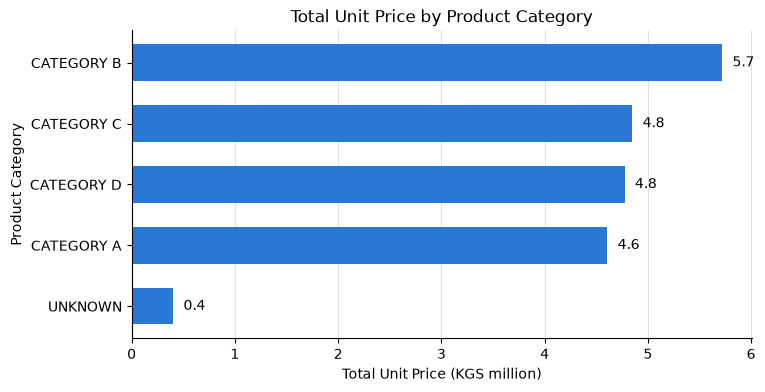

In [85]:
# chart 1: horizontal bar - total unit_price by Product Category
cat_total = df.groupby("product_category")["unit_price"].sum().sort_values()
vals = cat_total.values / 1e6

fig, ax = plt.subplots(figsize=(8, 4))
ax.barh(cat_total.index, vals, color=BLUE, height=0.6)
for y, v in enumerate(vals):
    ax.text(v + 0.1, y, f"{v:.1f}", va="center")
ax.set_title("Total Unit Price by Product Category")
ax.set_xlabel("Total Unit Price (KGS million)")
ax.set_ylabel("Product Category")
tidy(ax, "x")
plt.show()

**Insight:** **Category B** is the largest category with about 5.7 million KGS, followed by C (4.8 M), D (4.8 M) and A (4.6 M). B leads by about 18% over the second one, so it is the leader but it does not dominate. `UNKNOWN` (0.4 M) is not a product group but the records without a category.

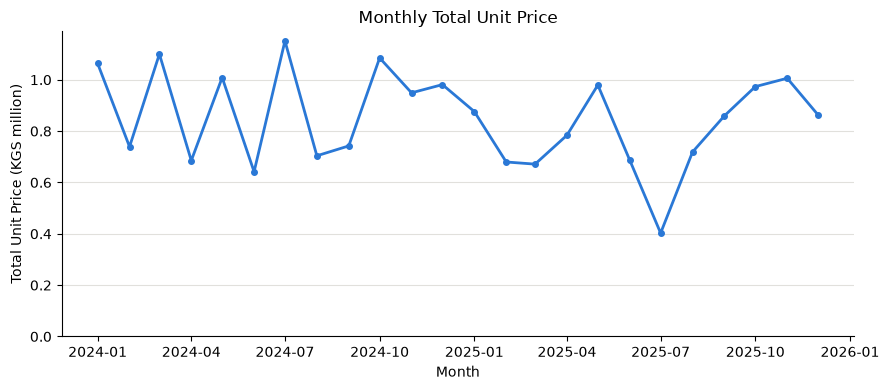

best month : 2024-07 1.15 M
worst month: 2025-07 0.4 M
months: 24 | mean per month: 0.85 M
first 12 months total: 10.85 M | last 12 months total: 9.5 M


In [74]:
# chart 2: line - total unit_price by month
monthly = df.set_index("order_date")["unit_price"].resample("MS").sum()

fig, ax = plt.subplots(figsize=(9, 4))
ax.plot(monthly.index, monthly.values / 1e6, color=BLUE, linewidth=2, marker="o", markersize=4)
ax.set_title("Monthly Total Unit Price")
ax.set_xlabel("Month")
ax.set_ylabel("Total Unit Price (KGS million)")
ax.set_ylim(0)
tidy(ax)
plt.tight_layout()
plt.show()
print("best month :", monthly.idxmax().strftime("%Y-%m"), round(monthly.max() / 1e6, 2), "M")
print("worst month:", monthly.idxmin().strftime("%Y-%m"), round(monthly.min() / 1e6, 2), "M")
print("months:", len(monthly), "| mean per month:", round(monthly.mean() / 1e6, 2), "M")
print("first 12 months total:", round(monthly.iloc[:12].sum() / 1e6, 2), "M | last 12 months total:", round(monthly.iloc[-12:].sum() / 1e6, 2), "M")

**Insight:** monthly revenue moves a lot, from 0.40 M (July 2025, the lowest) to 1.15 M (July 2024, the highest), around an average of 0.85 M per month. There is no steady growth: 2025 earned **9.5 M against 10.85 M in 2024 (-12.4%)**. The autumn of 2025 recovers to about 1 M per month (October 0.97 M, November 1.01 M), but the first half of the year and especially July 2025 were weak.

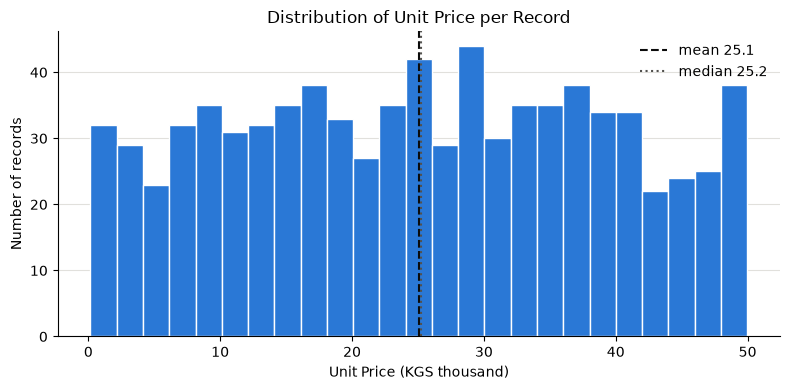

skewness: 0.003


In [83]:
# chart 3: histogram of unit_price per record
fig, ax = plt.subplots(figsize=(8, 4))
ax.hist(df["unit_price"] / 1000, bins=25, color=BLUE, edgecolor="white")
ax.axvline(df["unit_price"].mean() / 1000, color="#0b0b0b", linestyle="--", linewidth=1.5,
           label=f"mean {df['unit_price'].mean() / 1000:.1f}")
ax.axvline(df["unit_price"].median() / 1000, color="#52514e", linestyle=":", linewidth=1.5,
           label=f"median {df['unit_price'].median() / 1000:.1f}")
ax.set_title("Distribution of Unit Price per Record")
ax.set_xlabel("Unit Price (KGS thousand)")
ax.set_ylabel("Number of records")
ax.legend(frameon=False)
tidy(ax)
plt.tight_layout()
plt.show()
print("skewness:", round(df["unit_price"].skew(), 3))

**Insight:** after removing the outliers, `unit_price` is spread almost evenly from about 0 to 50,000 KGS. The mean (25,063 KGS) and the median (25,219 KGS) are practically the same and the skewness is about 0.00, so the distribution is **symmetric, with no real skew** and no single "typical" price level. A typical record is worth about 25 thousand KGS, but any value between small and 50 thousand is equally likely.

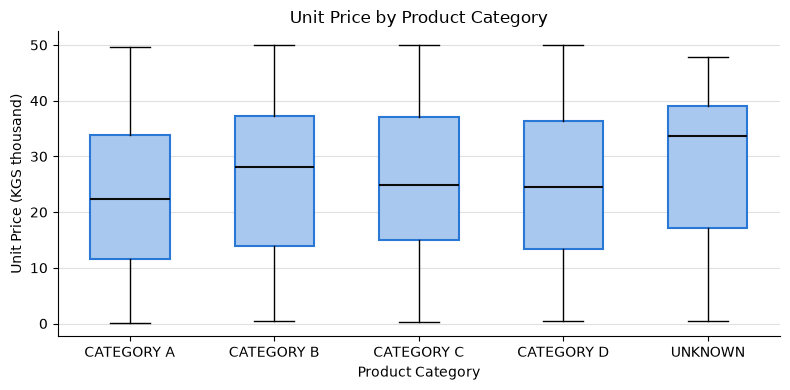

                  count   median  min    max      std
product_category                                     
CATEGORY A          199  22381.0  160  49644  13961.0
CATEGORY B          218  28090.0  391  49966  14171.0
CATEGORY C          189  24871.0  275  49956  13677.0
CATEGORY D          192  24570.0  420  49940  13760.0
UNKNOWN              14  33743.0  436  47779  14964.0


In [76]:
# chart 4: box plot of unit_price by Product Category
cats = sorted(df["product_category"].unique())
data = [df.loc[df["product_category"] == c, "unit_price"] / 1000 for c in cats]

fig, ax = plt.subplots(figsize=(8, 4))
bp = ax.boxplot(data, patch_artist=True, widths=0.55)
ax.set_xticklabels(cats)
for box in bp["boxes"]:
    box.set(facecolor="#a9c8ef", edgecolor=BLUE, linewidth=1.5)
for med in bp["medians"]:
    med.set(color="#0b0b0b", linewidth=1.5)
ax.set_title("Unit Price by Product Category")
ax.set_xlabel("Product Category")
ax.set_ylabel("Unit Price (KGS thousand)")
tidy(ax)
plt.tight_layout()
plt.show()
print(df.groupby("product_category")["unit_price"].agg(["count", "median", "min", "max", "std"]).round(0))

**Insight:** the categories are very similar in spread: the middle 50% of values (the box) covers about 22-23 thousand KGS in every category and the whiskers reach almost the whole range (from a few hundred to about 50,000 KGS). Medians differ more: B is the highest of the four real categories (28.1 thousand) and A the lowest (22.4 thousand). `UNKNOWN` has a high median (33.7 thousand) but only 14 records. No points appear beyond the whiskers because the outliers were removed earlier.

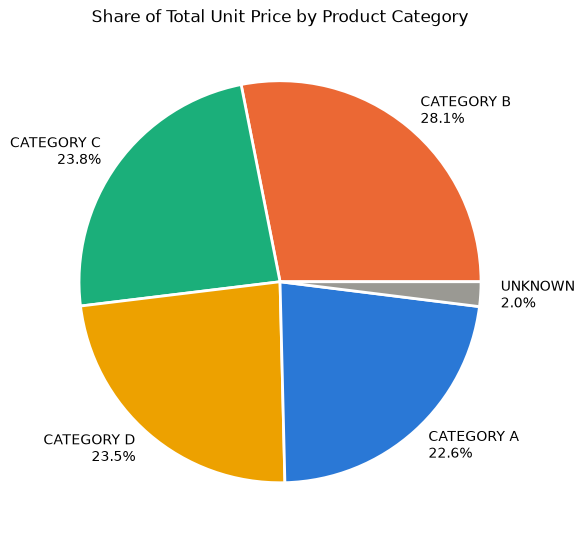

product_category
CATEGORY B    28.10
CATEGORY C    23.83
CATEGORY D    23.46
CATEGORY A    22.64
UNKNOWN        1.97
Name: unit_price, dtype: float64


In [82]:
# chart 5: pie - share of total unit_price by Product Category
share = df.groupby("product_category")["unit_price"].sum().sort_values(ascending=False)

fig, ax = plt.subplots(figsize=(6, 6))
pie_labels = [f"{name}\n{v / share.sum() * 100:.1f}%" for name, v in share.items()]
ax.pie(share.values, labels=pie_labels,
       colors=[CAT_COLORS[c] for c in share.index],
       wedgeprops={"edgecolor": "white", "linewidth": 2})
ax.set_title("Share of Total Unit Price by Product Category")
plt.tight_layout()
plt.show()
print((share / share.sum() * 100).round(2))

**Insight:** unit price is **not concentrated**: B 28.1%, C 23.8%, D 23.5%, A 22.6%, UNKNOWN 2.0%. Each of the four categories brings about a quarter of the total, and the two biggest (B and C) together bring 51.9%. The business does not depend on one product group.

---
# Task 5. Business Interpretation

In [86]:
# numbers used in the interpretation
total = df["unit_price"].sum()
print("total:", total, "| records:", len(df), "| mean:", round(df["unit_price"].mean()), "| max:", df["unit_price"].max())
print()
for col in ["product_category", "loyalty_points_used", "shop_branch", "payment_method", "customer_type"]:
    g = df.groupby(col)["unit_price"].agg(total="sum", mean="mean", max="max", records="count")
    g["share_%"] = (g["total"] / total * 100).round(1)
    print(g.sort_values("total", ascending=False).round(0))
    print()
print("quantity by category:")
print(df.groupby("product_category")["quantity"].agg(["sum", "mean"]).round(1))
print()
print(df.groupby("priority")["unit_price"].agg(["sum", "mean", "count"]).round(0))
print(df.groupby("business_segment")["unit_price"].agg(["sum", "mean", "count"]).round(0))

total: 20351538 | records: 812 | mean: 25063 | max: 49966

                    total     mean    max  records  share_%
product_category                                           
CATEGORY B        5719034  26234.0  49966      218     28.0
CATEGORY C        4849260  25657.0  49956      189     24.0
CATEGORY D        4774208  24866.0  49940      192     24.0
CATEGORY A        4607275  23152.0  49644      199     23.0
UNKNOWN            401761  28697.0  47779       14      2.0

                       total     mean    max  records  share_%
loyalty_points_used                                           
Bishkek              4712391  26775.0  49956      176     23.0
Karakol              4084476  24458.0  49966      167     20.0
Jalal-Abad           4084367  24905.0  49700      164     20.0
Tokmok               3901779  24695.0  49084      158     19.0
Osh                  3568525  24276.0  49902      147     18.0

               total     mean    max  records  share_%
shop_branch            

### 1. Three important business patterns

1. **Revenue is evenly spread over the product categories, with B in front.** Category B brings 5.72 M KGS (28.1% of the 20.35 M total), against 23.8% for C, 23.5% for D and 22.6% for A. B also has the highest average per record (26,234 KGS against 23,152 for A) and is the most frequent category (218 records).
2. **Location matters more than category.** Bishkek totals 4.71 M KGS (23.2%) and Osh 3.57 M (17.5%), a gap of 1.14 M (32%). The combination effect is even bigger: Tokmok sells 1.38 M of Category B but only 0.70 M of Category D.
3. **Revenue is unstable and fell in 2025.** Monthly totals range from 0.40 M to 1.15 M, and 2025 was 12.4% below 2024 (9.50 M against 10.85 M). The key indicator Maximum is about 50,000 KGS in every group, so single large orders do not explain the differences; the totals and averages do.

### 2. Strongest and weakest areas

| Group | Strongest | Weakest |
|---|---|---|
| `Loyalty Points Used` (location) | **Bishkek**: 4,712,391 KGS, 23.2%, mean 26,775 | **Osh**: 3,568,525 KGS, 17.5%, mean 24,276 |
| `Product Category` | **Category B**: 5,719,034 KGS, 28.1% | **Category A**: 4,607,275 KGS, 22.6% (`UNKNOWN` is lower, but it is a data gap, not a product) |
| Location x category cell | Tokmok x B: 1,376,776 KGS | Tokmok x D: 696,663 KGS |

By `Shop Branch` the picture differs: Osh branch is the best (4.65 M) and Bishkek branch is the weakest (3.46 M), so where the customer comes from and where the shop is are different things.

### 3. Recommendations

1. **Improve the data entry before the next analysis.** 14 records (401,761 KGS, 2.0% of the total) have no category, so they cannot be assigned to a segment, and 9 records had amounts of 315,520-1,829,720 KGS, about 10.9 M KGS in total, which would have been roughly a third of the revenue in the raw data. Make `Product Category` mandatory and ask for confirmation of any `unit_price` above about 72,000 KGS.
2. **Target the weak spots with the strongest offers.** Osh (3.57 M, 17.5%) is 1.14 M KGS behind Bishkek: lifting it by half of that gap would add about 0.57 M KGS (+2.8% of the total). Push Category B (the best seller, 28.1%) in Osh and Karakol, and review the Category D offer in Tokmok (0.70 M against 1.38 M for B). Also investigate the weak summer 2025 (July: 0.40 M against 1.15 M a year earlier) to stop the 12.4% yearly decline.